# Chapter 7: Digital Twins and Simulation

**Aventum Round 1 prep · STRATEGY.md §5.5** · Time needed: about 75 minutes

This chapter **assembles** Chapters 1, 3, 4 and 6 into one working object: a small Digital Twin of an MGA's underwriting book. You'll use it to answer "what if" questions, validate it by replay, and see the causal trap that makes a naive twin give the wrong answer to a pricing question.

### Syllabus
| No. | Topic | Interview use |
|---|---|---|
| 7.1 | What a Digital Twin is, and its four ingredients | "Where would you start with a Digital Twin?" |
| 7.2 | Build a twin from logged data (underwriter policy + broker response + loss model) | "How would you build a twin of a broker or an underwriter?" |
| 7.3 | Validate by replay against history | "How do you know the twin is right?" |
| 7.4 | What-if 1: an appetite rule (auto-decline) | "Test a policy change before touching customers" |
| 7.5 | What-if 2: a price change, and the causal trap | "Why do twins need causal structure?" |

## 0. Setup

In [1]:
import numpy as np                  # linear algebra
import pandas as pd                 # data processing
import matplotlib.pyplot as plt     # plots
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import GradientBoostingRegressor

np.random.seed(42)
sigmoid = lambda z: 1 / (1 + np.exp(-z))
print("Ready")

Ready


---
## 7.1 What is a Digital Twin?

### Definition
A **Digital Twin** is a virtual model of a real entity or process, **kept in sync with real data**, that you can run forward to **simulate "what if" scenarios** before changing anything in the real world.

| Twin of… | State | Behaviour to model | Example question |
|---|---|---|---|
| An **underwriter** | Submission features, workload | Quote / refer / decline policy (Chapter 3, BC) | "What if we auto-route small Property risks?" |
| A **broker** | Relationship history, portal events | Submit, respond to a quote, bind (Chapters 1 and 3) | "What if we respond 2 days faster?" |
| The **submission pipeline** | Queue lengths, stages | Transition probabilities, timings (Chapter 1, Markov) | "Where's the bottleneck if volume rises 30%?" |
| A **portfolio** | Bound risks, exposures | Losses, accumulations | "What does a 10% rate rise do to GWP and loss ratio?" |

### The four ingredients (the formula of this chapter)
$$\boxed{\text{Twin} = \underbrace{\text{state model}}_{\text{Ch 1}} + \underbrace{\text{behaviour policies}}_{\text{Ch 3}} + \underbrace{\text{causal structure}}_{\text{Ch 4}} + \underbrace{\text{validation by replay}}_{\text{Ch 6}}}$$

> **Note:** a twin is only as good as its weakest behavioural model, and **only causal models answer "what if I change X"**. A purely predictive model answers "what usually happens when X is high", which is a different question (§7.5).

### Solved Example 7.1 (computing a twin's KPI by hand)
**Q.** The twin's models say:

| Sub | P(quote) | P(bind ∣ quoted) | Premium (£k) |
|---|---|---|---|
| 1 | 0.9 | 0.5 | 100 |
| 2 | 0.6 | 0.4 | 200 |
| 3 | 0.3 | 0.2 | 500 |

(a) Expected GWP (gross written premium)? (b) Expected GWP if a new appetite rule auto-declines sub 3?

**Solution.** Expected GWP = $\sum_i P(\text{quote}_i)\,P(\text{bind}_i \mid \text{quote})\,\text{premium}_i$
(a) 0.9(0.5)(100) + 0.6(0.4)(200) + 0.3(0.2)(500) = 45 + 48 + 30 = **£123k**
(b) Sub 3 contributes 0: 45 + 48 = **£93k**

**Ans.** The rule costs £30k of expected GWP. The real question is whether it saves more than that in losses, which is what the loss model is for.

In [2]:
pq = np.array([0.9, 0.6, 0.3]); pb = np.array([0.5, 0.4, 0.2]); prem = np.array([100, 200, 500])
print("(a)", (pq * pb * prem).sum(), " (b)", (pq * pb * prem)[:2].sum())

(a) 123.0  (b) 93.0


---
## 7.2 The "real world" and the data it leaves behind

We write a **ground-truth simulator** for the real world. In real life you never have this; here it lets us **grade the twin**. The twin will only see the **logged data** it produces.

**How the real world works (hidden from the twin):**
- Each submission has a `risk_score` $q$ (higher = better risk), driven by prior claims and line of business.
- **Underwriters** quote good risks more, and prefer tier-A brokers.
- **Underwriters set the price loading** (1.00 = technical price): **good risks get lower loadings**.
- **Brokers bind** less when the loading is high (**true price sensitivity: −6 per unit of loading**), and **good risks bind less** because they have many competing offers.
- **Losses** are lower for good risks.

In [3]:
TIERS = ["A", "B", "C"]; LOBS = ["Property", "Marine", "Cyber"]

def make_submissions(n, seed):
    r = np.random.default_rng(seed)
    d = pd.DataFrame({
        "tier": r.choice(TIERS, n, p=[0.3, 0.4, 0.3]),
        "lob": r.choice(LOBS, n, p=[0.5, 0.3, 0.2]),
        "prior_claims": r.poisson(1.0, n),
        "base_premium": np.round(r.lognormal(np.log(60), 0.6, n), 1),      # £k technical premium
    })
    d["risk_score"] = (-0.6 * d.prior_claims - d.lob.map({"Property": 0, "Marine": 0.3, "Cyber": 0.8})
                       + r.normal(0, 0.7, n) + 0.6)
    return d

TRUE_PRICE_SENS = -6.0

def true_world(d, seed, auto_decline=None, loading_mult=1.0):
    """The REAL world's expected outcomes (and one random draw for the log)."""
    r = np.random.default_rng(seed)
    tier_pref = d.tier.map({"A": 0.6, "B": 0.2, "C": -0.4})
    p_quote = sigmoid(0.8 + 1.2 * d.risk_score + tier_pref)
    if auto_decline is not None:
        p_quote = np.where(auto_decline(d), 0.0, p_quote)
    loading = (1.0 - 0.15 * d.risk_score + r.normal(0, 0.05, len(d))) * loading_mult
    p_bind = sigmoid(0.3 + tier_pref + TRUE_PRICE_SENS * (loading - 1) - 0.8 * d.risk_score)
    exp_loss_ratio_tech = 0.65 * np.exp(-0.4 * d.risk_score)            # loss / technical premium
    out = d.copy()
    out["loading"] = loading
    out["quoted"] = r.random(len(d)) < p_quote
    out["bound"] = out.quoted & (r.random(len(d)) < p_bind)
    out["premium"] = d.base_premium * loading
    out["loss"] = np.where(out.bound, d.base_premium * exp_loss_ratio_tech * r.gamma(2, 0.5, len(d)), 0.0)
    # expected KPIs (exact, no sampling noise): used to grade the twin
    exp_bind = p_quote * p_bind
    kpi = {"quote rate": p_quote.mean(), "bind rate": exp_bind.mean(),
           "GWP £m": (exp_bind * out.premium).sum() / 1000,
           "loss ratio": (exp_bind * d.base_premium * exp_loss_ratio_tech).sum() / (exp_bind * out.premium).sum()}
    return out, kpi

hist_subs = make_submissions(20000, seed=1)
history, kpi_hist = true_world(hist_subs, seed=2)
history.head()

,tier,lob,prior_claims,base_premium,risk_score,loading,quoted,bound,premium,loss
0,B,Property,0,13.2,1.240016,0.823450,True,False,10.869543,0.000000
1,C,Property,0,54.6,0.704315,0.868215,False,False,47.404560,0.000000
2,A,Property,0,59.6,1.132932,0.809407,True,True,48.240655,12.172055
3,C,Property,0,90.3,0.950966,0.735282,False,False,66.395945,0.000000
4,B,Property,0,144.1,0.772446,0.974119,True,False,140.370479,0.000000


#### Program 7.2: build the twin from the log (three behavioural models)

In [4]:
def features(d, cols):
    X = pd.get_dummies(d[cols], columns=[c for c in cols if not pd.api.types.is_numeric_dtype(d[c])], dtype=float)
    return X.reindex(columns=sorted(X.columns), fill_value=0.0)

# (1) underwriter policy: behavioural cloning of quote / no quote  (Chapter 3)
UW_COLS = ["tier", "lob", "prior_claims", "risk_score"]
uw_model = LogisticRegression(max_iter=2000).fit(features(history, UW_COLS), history.quoted)

# (2) broker response: P(bind | quoted, loading, ...). Two versions:
q = history[history.quoted]
BROKER_NAIVE  = ["tier", "loading"]                    # "what predicts binding?"
BROKER_CAUSAL = ["tier", "loading", "risk_score"]      # includes the confounder of loading -> bind
# C=1e6 switches off sklearn's default L2 penalty, which would shrink the price coefficient
# (loading varies little, so its coefficient is cheap for the penalty to shrink)
broker_naive  = LogisticRegression(C=1e6, max_iter=5000).fit(features(q, BROKER_NAIVE), q.bound)
broker_causal = LogisticRegression(C=1e6, max_iter=5000).fit(features(q, BROKER_CAUSAL), q.bound)

# (3) loss model, fitted on BOUND risks only (selective labels, Chapter 3.3; fine here because
#     binding depends only on things we record)
b = history[history.bound]
LOSS_COLS = ["lob", "prior_claims", "risk_score"]
loss_model = GradientBoostingRegressor(random_state=0).fit(features(b, LOSS_COLS), b.loss / b.base_premium)

coef = dict(zip(features(q, BROKER_NAIVE).columns, broker_naive.coef_[0]))
coef_c = dict(zip(features(q, BROKER_CAUSAL).columns, broker_causal.coef_[0]))
print(f"price sensitivity learned by NAIVE broker model : {coef['loading']:+.2f}")
print(f"price sensitivity learned by CAUSAL broker model: {coef_c['loading']:+.2f}")
print(f"TRUE price sensitivity                          : {TRUE_PRICE_SENS:+.2f}")

price sensitivity learned by NAIVE broker model : -1.29
price sensitivity learned by CAUSAL broker model: -5.69
TRUE price sensitivity                          : -6.00


#### Explanation
- Both broker models **predict** binding about equally well on historical data. But the naive model's price coefficient is far too weak.
- **Why:** underwriters gave **good** risks **low** loadings, and good risks bind **less** (competition). In the log, low price goes with low bind, which masks the true price effect. `risk_score` is a **confounder** of loading → bind (Chapter 4). Including it recovers the true sensitivity.
- **Remember this result. It decides §7.5.**

In [5]:
def twin(d, broker_model, broker_cols, auto_decline=None, loading_mult=1.0, seed=3):
    """The twin's EXPECTED KPIs for a set of submissions under a policy."""
    r = np.random.default_rng(seed)
    p_quote = uw_model.predict_proba(features(d, UW_COLS))[:, 1]
    if auto_decline is not None:
        p_quote = np.where(auto_decline(d), 0.0, p_quote)
    dd = d.copy()
    dd["loading"] = (1.0 - 0.15 * d.risk_score + r.normal(0, 0.05, len(d))) * loading_mult  # current pricing rule
    p_bind = broker_model.predict_proba(features(dd, broker_cols))[:, 1]
    loss_ratio_tech = loss_model.predict(features(d, LOSS_COLS))
    exp_bind = p_quote * p_bind
    prem = d.base_premium * dd.loading
    return {"quote rate": p_quote.mean(), "bind rate": exp_bind.mean(),
            "GWP £m": (exp_bind * prem).sum() / 1000,
            "loss ratio": (exp_bind * d.base_premium * loss_ratio_tech).sum() / (exp_bind * prem).sum()}

> **Note (assumption made explicit):** the twin knows the **pricing rule** (`loading = 1 − 0.15·risk_score`), because it's Aventum's own rule and can be read from the rating engine. Twins combine **known mechanics** (your own rules) with **learned behaviour** (other people's responses).

---
## 7.3 Validate the twin by replay
Run the twin on **next quarter's** submissions under the **current** policy and compare it with what the real world does. If the twin can't reproduce the status quo, don't trust its what-ifs.

In [6]:
new_subs = make_submissions(8000, seed=10)
_, kpi_real_now = true_world(new_subs, seed=11)
kpi_twin_now = twin(new_subs, broker_causal, BROKER_CAUSAL)

val = pd.DataFrame({"real world": kpi_real_now, "twin": kpi_twin_now})
val["error %"] = 100 * (val["twin"] / val["real world"] - 1)
val.round(3)

,real world,twin,error %
quote rate,0.623,0.621,-0.347
bind rate,0.382,0.383,0.056
GWP £m,214.293,214.247,-0.021
loss ratio,0.673,0.668,-0.742


#### Explanation
Errors of a few percent on every KPI mean the twin passes replay validation for the **status quo**. In practice you'd also check by **segment** (line of business, broker tier) and over several time periods, just like the shadow-mode report in Chapter 6.

---
## 7.4 What-if 1: an appetite rule
**Proposal:** auto-decline Cyber risks with 2 or more prior claims. What happens to GWP and loss ratio?

In [7]:
rule = lambda d: (d.lob == "Cyber") & (d.prior_claims >= 2)
print(f"share of submissions hit by the rule: {rule(new_subs).mean():.1%}")

_, kpi_real_rule = true_world(new_subs, seed=11, auto_decline=rule)
kpi_twin_rule = twin(new_subs, broker_causal, BROKER_CAUSAL, auto_decline=rule)

wi1 = pd.DataFrame({
    "twin: change": {k: kpi_twin_rule[k] - kpi_twin_now[k] for k in kpi_twin_now},
    "real world: change": {k: kpi_real_rule[k] - kpi_real_now[k] for k in kpi_real_now},
})
wi1.round(4)

share of submissions hit by the rule: 5.1%


,twin: change,real world: change
quote rate,-0.0153,-0.0152
bind rate,-0.0091,-0.0091
GWP £m,-6.6115,-6.6031
loss ratio,-0.0069,-0.0079


The twin correctly predicts a small loss of GWP and an improvement in loss ratio, of about the right size. **This kind of change (who gets quoted) is safe for the twin**, because the underwriter policy is something Aventum *sets*, and the rest of the chain (broker response, losses) is unchanged.

---
## 7.5 What-if 2: a 10% price rise, and the causal trap
**Proposal:** raise all loadings by 10%. Compare the **naive** twin (broker model without the confounder) and the **causal** twin with the real world.

In [8]:
_, kpi_real_price = true_world(new_subs, seed=11, loading_mult=1.10)
naive_now   = twin(new_subs, broker_naive, BROKER_NAIVE)
naive_price = twin(new_subs, broker_naive, BROKER_NAIVE, loading_mult=1.10)
causal_price = twin(new_subs, broker_causal, BROKER_CAUSAL, loading_mult=1.10)

pct = lambda after, before, k: 100 * (after[k] / before[k] - 1)
wi2 = pd.DataFrame({
    "naive twin": {k: pct(naive_price, naive_now, k) for k in ["bind rate", "GWP £m"]},
    "causal twin": {k: pct(causal_price, kpi_twin_now, k) for k in ["bind rate", "GWP £m"]},
    "real world": {k: pct(kpi_real_price, kpi_real_now, k) for k in ["bind rate", "GWP £m"]},
})
print("% change from a +10% price rise")
wi2.round(1)

% change from a +10% price rise


,naive twin,causal twin,real world
bind rate,-4.8,-21.2,-22.5
GWP £m,4.6,-13.9,-15.5


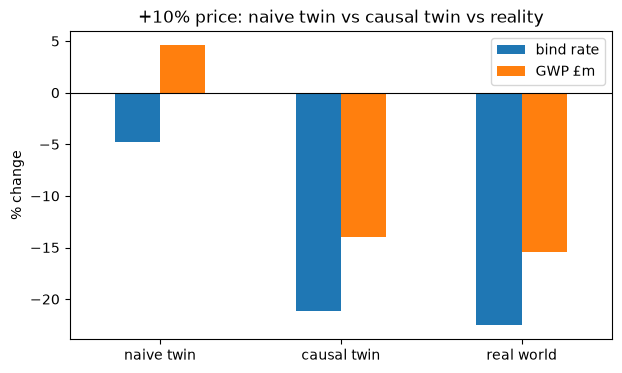

In [9]:
wi2.T.plot(kind="bar", figsize=(7, 4), rot=0)
plt.axhline(0, color="black", lw=0.8); plt.ylabel("% change"); plt.title("+10% price: naive twin vs causal twin vs reality")
plt.show()

#### Explanation (the most important cell in the chapter)
- The **naive twin** says a 10% price rise barely dents binding, so **GWP goes up**. A pricing committee would love this answer.
- The **real world** loses a large share of binds, and GWP falls.
- The **causal twin**, whose broker model includes the confounder, gets the direction and the size about right.
- **Both twins passed replay validation for the status quo** (§7.3 checked only the causal one, but the naive one also predicts current binds well). **Replay validation can't detect this error**, because the problem only appears when you *intervene* on price. That's the gap between prediction and causation.

**How to protect a real twin against this:**
1. Draw the DAG for every lever you intend to pull (price, appetite, speed) and make sure each behavioural model adjusts for that lever's confounders.
2. Look for **exogenous variation** in the lever: random price tests, rate changes applied across the board on a date (diff-in-diff), quoting-system outages.
3. Where possible, validate the twin against **past interventions** (an old rate change) rather than only the status quo.

---
## Exercise 7.1
1. In Solved Example 7.1, the auto-decline rule also cuts expected losses on sub 3 by £40k. Is the rule worth it?
2. Why is an appetite rule a "safer" what-if for the twin than a price change?
3. The naive broker model has a good AUC. Why doesn't that protect you?
4. Name one real Aventum data source that would give exogenous price variation.
5. How would you build a **broker** twin from portal events (Chapter 1) and quote responses (this chapter)?

<details><summary><b>Answers</b></summary>

1. It loses £30k of expected GWP and saves £40k of expected losses, so yes, it adds about £10k of underwriting profit (ignoring expenses and the broker relationship).
2. The twin changes something Aventum controls directly (who gets quoted), and the downstream models see the same kind of inputs as before. A price change moves an input (loading) whose relationship with the outcome was confounded in the historical data.
3. AUC measures **prediction under the historical policy**. A what-if needs the **causal effect** of changing loading, which a confounded model gets wrong while still predicting well.
4. A market-wide rate change applied on a date (diff-in-diff), a deliberate small randomised price test, or rating-engine version changes rolled out by line of business.
5. State: portal event sequences plus relationship history. Behaviour: an HMM or LSTM for intent (shopping vs ready), and a response model for P(bind ∣ quote, price, speed) with confounders. Validate by replay of past quarters, then test against any historical intervention.
</details>

## Viva / Interview Questions
**Q. Where would you start with a Digital Twin?**
I'd start by asking what decision it's for, because that fixes the levers. Then I'd start small and validated: one process (say submission triage) with a transition model, an underwriter policy cloned from logs and a broker response model, then check that it reproduces the status quo by replay. Before using it for a what-if, I'd check the causal structure for that lever. A twin that predicts well can still give the wrong answer when you change price.

**Q. How do you know the twin is right?**
Replay against held-out periods, by segment. Then, more importantly, back-test against past interventions where we know what happened. Then shadow its recommendations. And always report it as a range, not a point.

## How to say it on Friday
> "I built a toy twin this week to see how the pieces fit: a cloned underwriter policy, a broker response model and a loss model. What surprised me was that a naive broker model passed replay validation but got a price change badly wrong, because good risks got lower prices and also bound less. So I'd want causal structure behind any lever the twin is used to test."